# Workbook Exercise: Breast Cancer Diagnosis — An End-to-End Classification Project

**Course:** Machine Learning / Applied AI  **Level:** Intermediate  **Estimated time:** 2 hours

**Learning objectives.** By the end of this workbook you will be able to:
1. Frame a real-world problem as a supervised learning task.
2. Summarize and visualize a dataset to understand its structure before modeling.
3. Clean data, select informative features and apply appropriate transforms.
4. Build a leak-free test harness and spot-check several algorithms.
5. Improve accuracy through tuning and ensembles, then report honest test results.

**How to use this workbook.** Run the cells in order. Wherever you see `# TODO`, replace the `...` with your own code (hints are given). Cells marked ✏️ ask for a written answer: double-click to edit. Do not look at the answer key until you have tried each exercise.

**Outline**
- A. Problem Definition
- B. Summarize and Analyze Data
- C. Prepare Data
- D. Evaluate Algorithm
- E. Improve Accuracy



## Before you begin

> First, make a copy of this notebook so that you can make changes as you please.
> Run and edit the copy instead of this original notebook.

> To copy this notebook, go to `File|Save a Copy to Drive`.

**Gentle Reminder**
> Once finish, Kindly `push` this notebook to your GitHub repo.**

---
## A. Problem Definition

### A.1 Brief Description
The **Breast Cancer Wisconsin (Diagnostic)** dataset contains measurements computed from digitized images of fine-needle aspirates (FNA) of breast masses. Each row describes the characteristics of the cell nuclei present in one image.

- **569 instances**, **30 numeric features**, **1 binary target**
- Features are 10 nucleus measurements (radius, texture, perimeter, area, smoothness, compactness, concavity, concave points, symmetry, fractal dimension), each reported as the **mean**, the **standard error** and the **worst** (largest) value.
- Target: `0` = malignant, `1` = benign.

### A.2 Problem Statement
✏️ **Exercise A.1.** In 3–4 sentences, write a problem statement in your own words. Include: (a) the prediction task, (b) the input data, (c) the type of learning problem, (d) which kind of error is more costly and why, and (e) how you will judge success.

> **Your answer:** *This project addresses a supervised binary classification problem to predict whether a breast mass is malignant or benign using 30 numerical features describing cell nuclei characteristics (such as radius, texture, and area) derived from digitized fine needle aspiration (FNA) images. A false negative error (classifying a malignant tumor as benign) is significantly more costly than a false positive because missing a cancer diagnosis delays critical medical treatment and puts patient health at severe risk. Success will be judged primarily by achieving a high ROC-AUC score and strong Recall (sensitivity) to ensure minimal missed cancer cases, while maintaining a balanced precision to avoid unnecessary invasive follow-ups.*

### A.3 Load Packages
**Exercise A.2.** The imports below are mostly done. Add the classifier imports you will need in Parts C–E.

In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import (train_test_split, StratifiedKFold,
                                     cross_val_score, cross_validate, GridSearchCV)
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.pipeline import Pipeline
from sklearn.feature_selection import SelectKBest, f_classif, RFE
from sklearn.decomposition import PCA
from sklearn.metrics import (accuracy_score, classification_report,
                             ConfusionMatrixDisplay, make_scorer, recall_score)

# TODO: import LogisticRegression, LinearDiscriminantAnalysis, KNeighborsClassifier, DecisionTreeClassifier, GaussianNB, SVC, RandomForest, ExtraTrees, GradientBoosting, AdaBoost and VotingClassifier
...

try:
    display
except NameError:
    display = print

### A.4 Load Dataset
**Exercise A.3.** Load the data into a DataFrame named `df` (hint: `load_breast_cancer(as_frame=True)`).

> *Using your own data?* Only this cell changes. For an ARFF file use `scipy.io.arff.loadarff`, and keep the rest of the workbook as is.

> `url = [https://archive.ics.uci.edu/dataset/17/breast+cancer+wisconsin+diagnostic]`

In [40]:
import pandas as pd

from sklearn.datasets import load_breast_cancer

data = load_breast_cancer(as_frame=True)
df = data.frame

print("Rows, columns:", df.shape)
print("Classes:", list(data.target_names), "-> 0 = malignant, 1 = benign")

Rows, columns: (569, 31)
Classes: [np.str_('malignant'), np.str_('benign')] -> 0 = malignant, 1 = benign


---
## B. Summarize and Analyze Data

### B.1 Descriptive Statistics
**Exercise B.1.** Inspect the dataset's dimensions, data types and the first rows.

In [41]:
# TODO: print the shape, the counts of each dtype, and show the first 5 rows
...
print("\nShape:", df.shape)
print("Counts of each dtype:")
print(df.dtypes.value_counts())
print("\nFirst 5 rows:")
display(df.head())


Shape: (569, 31)
Counts of each dtype:
float64    30
int64       1
Name: count, dtype: int64

First 5 rows:


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,target
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,0
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,0
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,0
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,0
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,0


**Exercise B.2.** Check for class imbalance. Print the count and the proportion of each class.

In [42]:
# TODO: class counts and percentages
...

from sklearn.datasets import load_breast_cancer

cancer = load_breast_cancer(as_frame=True)
df = cancer.frame

print("Class Counts:")
print(df['target'].value_counts())

print("\nClass Percentages:")
print(df['target'].value_counts(normalize=True) * 100)


Class Counts:
target
1    357
0    212
Name: count, dtype: int64

Class Percentages:
target
1    62.741652
0    37.258348
Name: proportion, dtype: float64


**Exercise B.3.** Produce summary statistics (transposed so features are rows) and list the 10 most skewed features.

In [11]:
# TODO: describe().T, then the 10 largest skewness values
...

print("Summary Statistics (Transposed):")
display(df.describe().T)

Summary Statistics (Transposed):


,count,mean,std,min,25%,50%,75%,max
0,569.0,3.037183e+07,1.250206e+08,8670.000000,869218.000000,906024.000000,8.813129e+06,9.113205e+08
2,569.0,1.412729e+01,3.524049e+00,6.981000,11.700000,13.370000,1.578000e+01,2.811000e+01
3,569.0,1.928965e+01,4.301036e+00,9.710000,16.170000,18.840000,2.180000e+01,3.928000e+01
4,569.0,9.196903e+01,2.429898e+01,43.790000,75.170000,86.240000,1.041000e+02,1.885000e+02
5,569.0,6.548891e+02,3.519141e+02,143.500000,420.300000,551.100000,7.827000e+02,2.501000e+03
6,569.0,9.636028e-02,1.406413e-02,0.052630,0.086370,0.095870,1.053000e-01,1.634000e-01
7,569.0,1.043410e-01,5.281276e-02,0.019380,0.064920,0.092630,1.304000e-01,3.454000e-01
8,569.0,8.879932e-02,7.971981e-02,0.000000,0.029560,0.061540,1.307000e-01,4.268000e-01
9,569.0,4.891915e-02,3.880284e-02,0.000000,0.020310,0.033500,7.400000e-02,2.012000e-01
10,569.0,1.811619e-01,2.741428e-02,0.106000,0.161900,0.179200,1.957000e-01,3.040000e-01


**Exercise B.4.** Compute the correlation of every feature with the target and show the 5 most negative and 5 most positive.

In [23]:
# TODO: correlation with target, sorted
...

print("Correlation with target (sorted):")
target_corr = df.corr()['target'].sort_values(ascending=False)
print(target_corr)

Correlation with target (sorted):
target                     1.000000
smoothness error           0.067016
mean fractal dimension     0.012838
texture error              0.008303
symmetry error             0.006522
fractal dimension error   -0.077972
concavity error           -0.253730
compactness error         -0.292999
worst fractal dimension   -0.323872
mean symmetry             -0.330499
mean smoothness           -0.358560
concave points error      -0.408042
mean texture              -0.415185
worst symmetry            -0.416294
worst smoothness          -0.421465
worst texture             -0.456903
area error                -0.548236
perimeter error           -0.556141
radius error              -0.567134
worst compactness         -0.590998
mean compactness          -0.596534
worst concavity           -0.659610
mean concavity            -0.696360
mean area                 -0.708984
mean radius               -0.730029
worst area                -0.733825
mean perimeter            -0.7

✏️ **Question B.5.** What do the class proportions and the skewness tell you about the choice of evaluation metric and the need for transforms?

>**Class Proportions:** The class distribution is moderately imbalanced (roughly 37% malignant vs. 63% benign). This indicates that simple overall accuracy is a misleading evaluation metric because a naive model predicting the majority class would still look superficially accurate. Instead, we should use metrics like ROC-AUC, Precision, Recall, and the F1-score, with a strong emphasis on maximizing Recall (Sensitivity) to ensure malignant cases are not missed.

>**Skewness:** High skewness in several biometric features (such as cell area and perimeter measurements) shows that features span different magnitudes and long-tailed distributions. This tells us there is a clear need for feature scaling (e.g., StandardScaler or MinMaxScaler) and potentially log or power transformations, particularly for distance-based or regularized models (like Logistic Regression, SVMs, and k-NN), to prevent large-magnitude features from disproportionately dominating the objective function.*

### B.2 Data Visualization

**Exercise B.6 (univariate).** Plot histograms of the ten `mean` features.

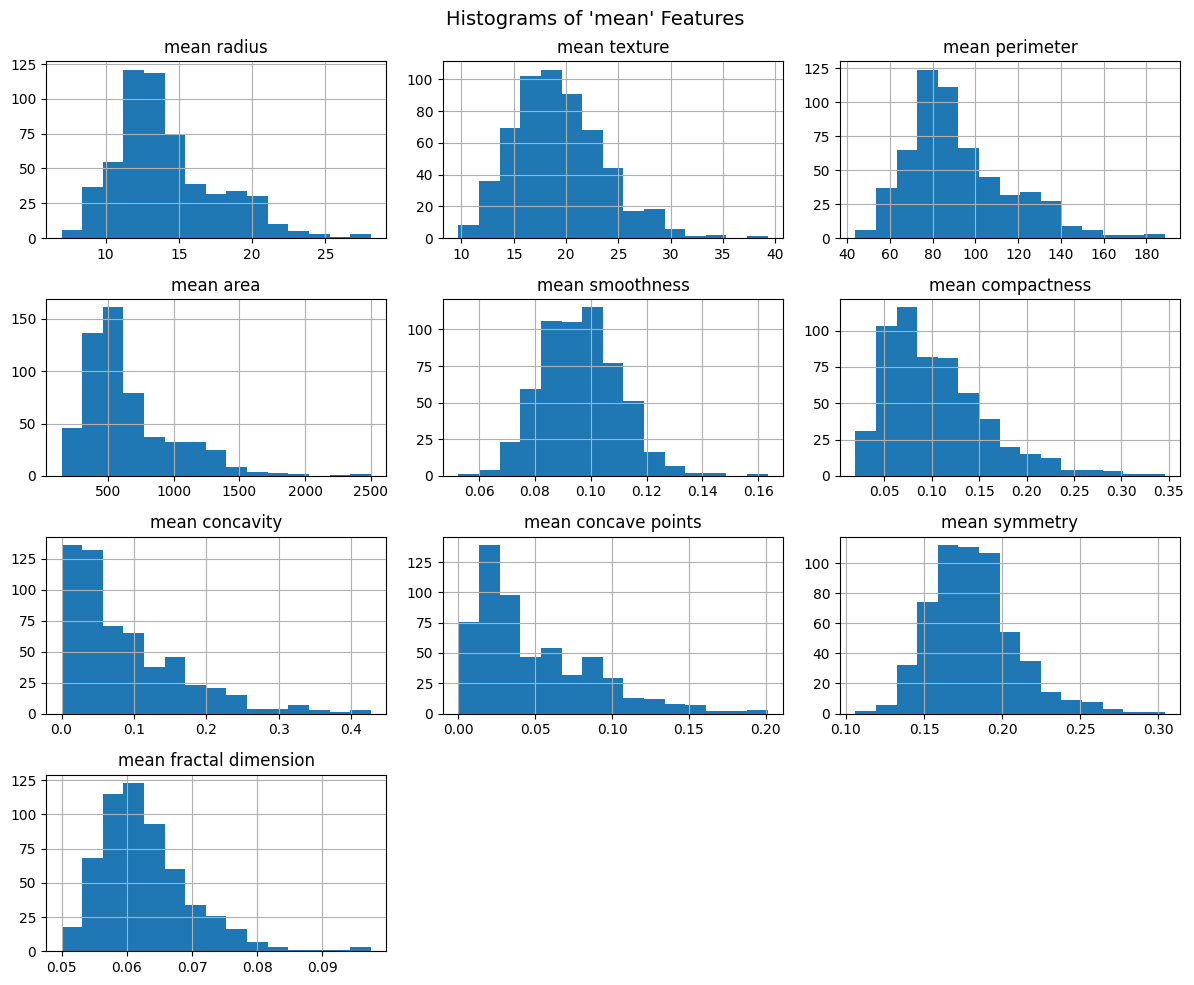

In [16]:
# TODO: histograms of the ten "mean" features (hint: df.filter(like="mean").hist)
...

import matplotlib.pyplot as plt

# Plot histograms for all features containing "mean"
df.filter(like="mean").hist(bins=15, figsize=(12, 10))
plt.suptitle("Histograms of 'mean' Features", fontsize=14)
plt.tight_layout()
plt.show()

**Exercise B.7 (bivariate).** Draw box plots of four features split by class. Which separate the classes best?

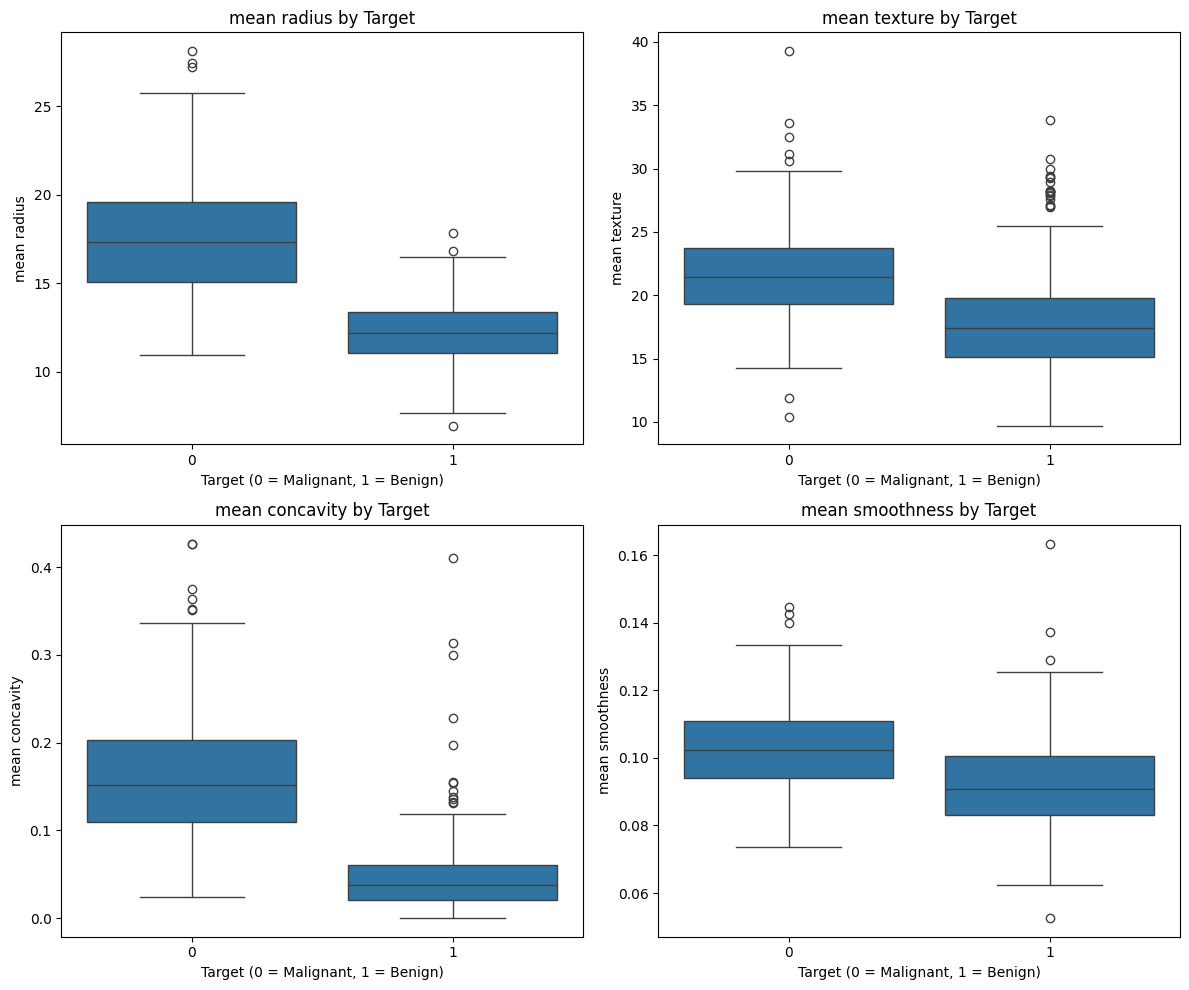

In [17]:
features = ["mean radius", "mean texture", "mean concavity", "mean smoothness"]
# TODO: one box plot per feature, grouped by target
...

import seaborn as sns
import matplotlib.pyplot as plt

features = ["mean radius", "mean texture", "mean concavity", "mean smoothness"]

# Create a 2x2 grid of box plots grouped by target
fig, axes = plt.subplots(2, 2, figsize=(12, 10))
for i, feat in enumerate(features):
    row, col = divmod(i, 2)
    sns.boxplot(x='target', y=feat, data=df, ax=axes[row, col])
    axes[row, col].set_title(f"{feat} by Target")
    axes[row, col].set_xlabel("Target (0 = Malignant, 1 = Benign)")

plt.tight_layout()
plt.show()

**Exercise B.8 (multivariate).** Show a correlation heatmap of the ten `mean` features.

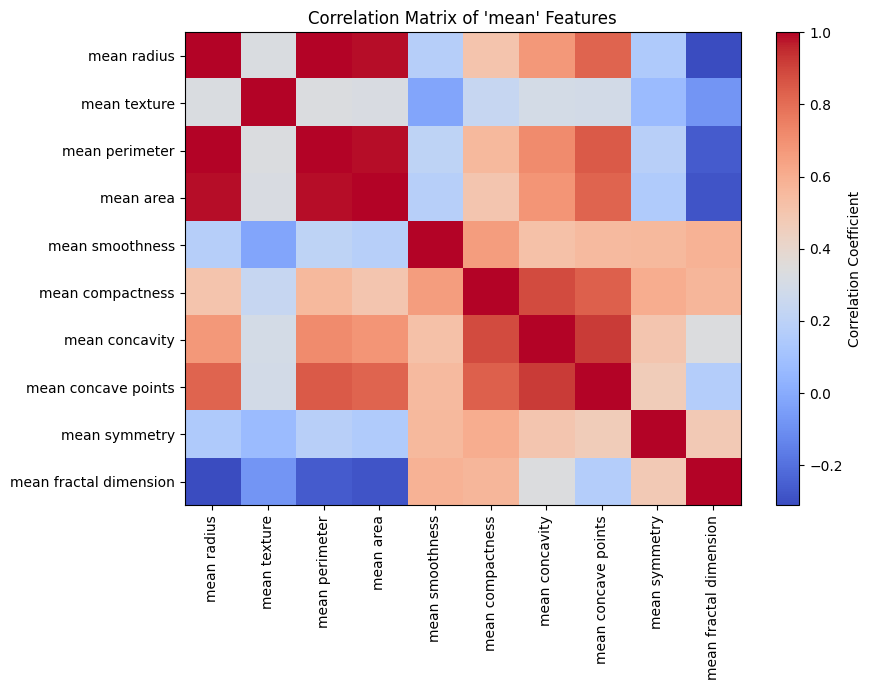

In [18]:
# TODO: correlation matrix of the "mean" features drawn with imshow
...

import matplotlib.pyplot as plt

# Filter 'mean' features and calculate correlation matrix
mean_df = df.filter(like="mean")
corr = mean_df.corr()

plt.figure(figsize=(9, 7))
plt.imshow(corr, cmap="coolwarm", aspect="auto")
plt.colorbar(label="Correlation Coefficient")
plt.xticks(range(len(corr.columns)), corr.columns, rotation=90)
plt.yticks(range(len(corr.index)), corr.index)
plt.title("Correlation Matrix of 'mean' Features")
plt.tight_layout()
plt.show()

**Exercise B.9.** Scatter `mean radius` against `mean concavity`, coloured by class.

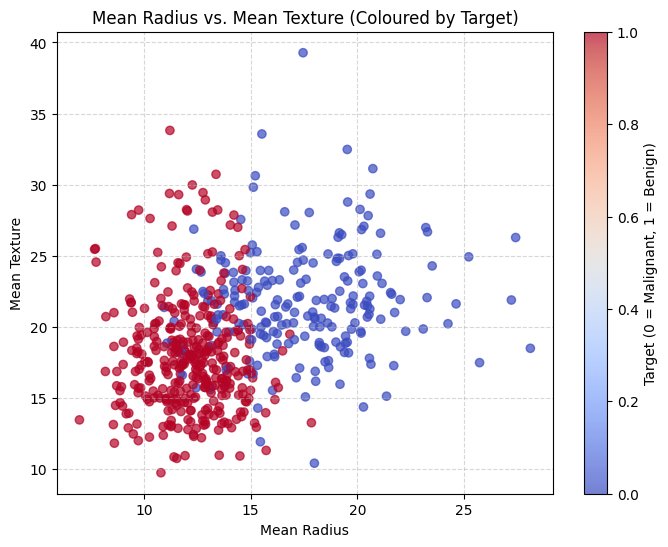

In [19]:
# TODO: coloured scatter plot with axis labels and a colourbar
...

import matplotlib.pyplot as plt

plt.figure(figsize=(8, 6))
scatter = plt.scatter(df['mean radius'], df['mean texture'], c=df['target'], cmap='coolwarm', alpha=0.7)
plt.xlabel('Mean Radius')
plt.ylabel('Mean Texture')
plt.title('Mean Radius vs. Mean Texture (Coloured by Target)')
plt.colorbar(scatter, label='Target (0 = Malignant, 1 = Benign)')
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

✏️ **Question B.10.** Which features appear redundant, and which separate the classes most clearly?

>**Redundant Features:** Geometric size measurements—specifically mean radius, mean perimeter, and mean area—appear highly redundant. Because these dimensions are mathematically linked (e.g., area and perimeter scale directly with radius), they show near-perfect correlation with one another in the correlation matrix, carrying much of the same underlying variance.*

>**Features that Separate Classes Most Clearly:** Features describing morphological irregularity and complexity—such as mean concavity, mean concave points, and mean radius—separate the classes most clearly. In the box plots and scatter plots, malignant tumors consistently exhibit significantly higher values, wider spreads, and distinct clustering compared to benign tumors, making them strong standalone indicators for classification.



---
## C. Prepare Data

### C.1 Data Cleaning
**Exercise C.1.** Count missing values and duplicate rows.

In [43]:
# TODO: total missing values and duplicated rows
...

print("Total missing values:", df.isnull().sum().sum())
print("Total duplicated rows:", df.duplicated().sum())

X = df.drop(columns="target")
y = df["target"]

Total missing values: 0
Total duplicated rows: 0


**Exercise C.2.** Count outliers per feature using the IQR rule (below Q1 − 1.5·IQR or above Q3 + 1.5·IQR) and show the 10 features with the most.

In [46]:
# TODO: IQR outlier count per feature
...

numeric_df = df.select_dtypes(include='number')
Q1 = numeric_df.quantile(0.25)
Q3 = numeric_df.quantile(0.75)
IQR = Q3 - Q1

outlier_counts = ((numeric_df < (Q1 - 1.5 * IQR)) | (numeric_df > (Q3 + 1.5 * IQR))).sum()
print("IQR outlier count per feature:")
print(outlier_counts)

print("\n" + "="*40 + "\n")

IQR outlier count per feature:
mean radius                14
mean texture                7
mean perimeter             13
mean area                  25
mean smoothness             6
mean compactness           16
mean concavity             18
mean concave points        10
mean symmetry              15
mean fractal dimension     15
radius error               38
texture error              20
perimeter error            38
area error                 65
smoothness error           30
compactness error          28
concavity error            22
concave points error       19
symmetry error             27
fractal dimension error    28
worst radius               17
worst texture               5
worst perimeter            15
worst area                 35
worst smoothness            7
worst compactness          16
worst concavity            12
worst concave points        0
worst symmetry             23
worst fractal dimension    24
target                      0
dtype: int64




✏️ **Question C.3.** Would you delete the outlying rows? Justify your decision.

> No, we should not delete the outlying rows.

>**Justification:**

>Genuine Biological Variance: In medical and biometric datasets, extreme values (outliers) often represent real-world clinical anomalies—such as aggressive, advanced malignant tumors with unusually large or irregular cell structures—rather than data collection errors or noise. Deleting them would discard critical diagnostic signals.

>Loss of Information: Removing these data points reduces the dataset's overall variance and can bias the model toward underestimating the true range of tumor characteristics, making it less robust to edge cases in clinical practice.

>Better Alternatives: Instead of deleting rows, it is safer to handle feature sensitivity by using robust scaling techniques (RobustScaler), tree-based algorithms (such as Random Forests or Gradient Boosting) that are naturally resilient to outliers, or keeping the data as-is if using regularized linear models.

### C.2 Feature Selection
**Exercise C.4 (filter).** Find features whose absolute correlation with an *earlier* feature exceeds 0.95.

In [49]:
# TODO: upper-triangle of the absolute correlation matrix, then columns above 0.95
...

corr_matrix = numeric_df.corr().abs()
upper_tri = corr_matrix.where(np.triu(np.ones(corr_matrix.shape), k=1).astype(bool))

print("Upper-triangle of absolute correlation matrix:")
display(upper_tri.head(10))

high_corr_columns = [col for col in upper_tri.columns if any(upper_tri[col] > 0.95)]
print("\nColumns with at least one correlation > 0.95 in the upper triangle:")
print(high_corr_columns)

Upper-triangle of absolute correlation matrix:


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,target
mean radius,NaN,0.323782,0.997855,0.987357,0.170581,0.506124,0.676764,0.822529,0.147741,0.311631,...,0.297008,0.965137,0.941082,0.119616,0.413463,0.526911,0.744214,0.163953,0.007066,0.730029
mean texture,NaN,NaN,0.329533,0.321086,0.023389,0.236702,0.302418,0.293464,0.071401,0.076437,...,0.912045,0.358040,0.343546,0.077503,0.277830,0.301025,0.295316,0.105008,0.119205,0.415185
mean perimeter,NaN,NaN,NaN,0.986507,0.207278,0.556936,0.716136,0.850977,0.183027,0.261477,...,0.303038,0.970387,0.941550,0.150549,0.455774,0.563879,0.771241,0.189115,0.051019,0.742636
mean area,NaN,NaN,NaN,NaN,0.177028,0.498502,0.685983,0.823269,0.151293,0.283110,...,0.287489,0.959120,0.959213,0.123523,0.390410,0.512606,0.722017,0.143570,0.003738,0.708984
mean smoothness,NaN,NaN,NaN,NaN,NaN,0.659123,0.521984,0.553695,0.557775,0.584792,...,0.036072,0.238853,0.206718,0.805324,0.472468,0.434926,0.503053,0.394309,0.499316,0.358560
mean compactness,NaN,NaN,NaN,NaN,NaN,NaN,0.883121,0.831135,0.602641,0.565369,...,0.248133,0.590210,0.509604,0.565541,0.865809,0.816275,0.815573,0.510223,0.687382,0.596534
mean concavity,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.921391,0.500667,0.336783,...,0.299879,0.729565,0.675987,0.448822,0.754968,0.884103,0.861323,0.409464,0.514930,0.696360
mean concave points,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.462497,0.166917,...,0.292752,0.855923,0.809630,0.452753,0.667454,0.752399,0.910155,0.375744,0.368661,0.776614
mean symmetry,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.479921,...,0.090651,0.219169,0.177193,0.426675,0.473200,0.433721,0.430297,0.699826,0.438413,0.330499
mean fractal dimension,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,0.051269,0.205151,0.231854,0.504942,0.458798,0.346234,0.175325,0.334019,0.767297,0.012838



Columns with at least one correlation > 0.95 in the upper triangle:
['mean perimeter', 'mean area', 'perimeter error', 'area error', 'worst radius', 'worst perimeter', 'worst area']


**Exercise C.5 (univariate).** Rank features with `SelectKBest(f_classif)`.

In [56]:
# TODO: fit SelectKBest(f_classif, k=10) and build a sorted Series of scores
...

from sklearn.feature_selection import SelectKBest, f_classif
import pandas as pd

selector = SelectKBest(score_func=f_classif, k=10)
selector.fit(X, y)

kbest_scores = pd.Series(selector.scores_, index=X.columns).sort_values(ascending=False)
print(kbest_scores.head(10))

worst concave points    964.385393
worst perimeter         897.944219
mean concave points     861.676020
worst radius            860.781707
mean perimeter          697.235272
worst area              661.600206
mean radius             646.981021
mean area               573.060747
mean concavity          533.793126
worst concavity         436.691939
dtype: float64


**Exercise C.6 (wrapper).** Use Recursive Feature Elimination with logistic regression on standardized data to keep 10 features.

In [63]:
# TODO: RFE(LogisticRegression, n_features_to_select=10) on standardised X; store names in rfe_features
...

from sklearn.feature_selection import RFE
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler

# Ensure features are standardized for Logistic Regression convergence
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)
X_scaled_df = pd.DataFrame(X_scaled, columns=X.columns)

# Fit RFE with Logistic Regression estimator
estimator = LogisticRegression(max_iter=10000, random_state=7)
rfe = RFE(estimator=estimator, n_features_to_select=10)
rfe.fit(X_scaled_df, y)

# Store selected feature names in rfe_features
rfe_features = X.columns[rfe.support_].tolist()
print("RFE Selected Features (top 10):")
print(rfe_features)

RFE Selected Features (top 10):
['mean concave points', 'radius error', 'area error', 'compactness error', 'worst radius', 'worst texture', 'worst perimeter', 'worst area', 'worst concavity', 'worst concave points']


**Exercise C.7 (embedded).** Rank features by `ExtraTreesClassifier` importance and plot the top 10.

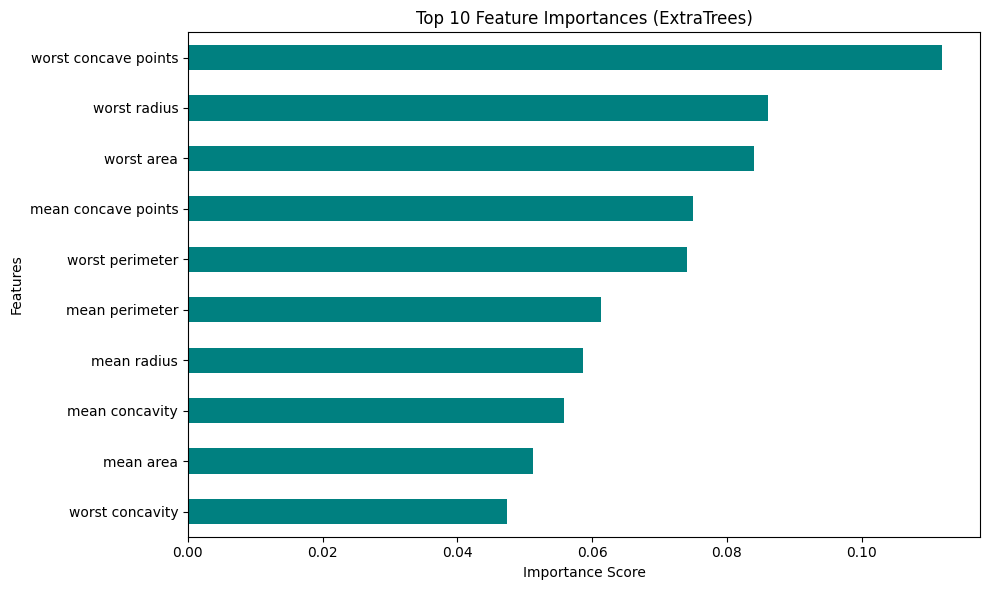

In [54]:
# TODO: fit ExtraTrees (200 trees, random_state=7), store importances in imp, plot barh of top 10
...

from sklearn.ensemble import ExtraTreesClassifier
import matplotlib.pyplot as plt

et_model = ExtraTreesClassifier(n_estimators=200, random_state=7)
et_model.fit(X, y)

imp = pd.Series(et_model.feature_importances_, index=X.columns).sort_values(ascending=True)

plt.figure(figsize=(10, 6))
imp.tail(10).plot(kind='barh', color='teal')
plt.title('Top 10 Feature Importances (ExtraTrees)')
plt.xlabel('Importance Score')
plt.ylabel('Features')
plt.tight_layout()
plt.show()

**Exercise C.8 (decision).** Keep a feature if **at least two of the three** methods (SelectKBest top 10, RFE, ExtraTrees top 10) chose it. Store the result in a list called `selected`.

In [55]:
# TODO: vote across the three methods
...

kbest_top10 = kbest_scores.head(10).index.tolist()
et_top10 = imp.tail(10).index.tolist()


all_selected = kbest_top10 + rfe_features + et_top10
vote_counts = pd.Series(all_selected).value_counts()

print("Feature Consensus (Votes across methods):")
print(vote_counts)

consensus_features = vote_counts[vote_counts >= 2].index.tolist()
print("\nFinal Consensus Features (voted by >= 2 methods):")
print(consensus_features)

Feature Consensus (Votes across methods):
worst concave points    3
worst perimeter         3
mean concave points     3
worst radius            3
worst area              3
worst concavity         3
mean perimeter          2
mean radius             2
mean area               2
mean concavity          2
radius error            1
area error              1
compactness error       1
worst texture           1
Name: count, dtype: int64

Final Consensus Features (voted by >= 2 methods):
['worst concave points', 'worst perimeter', 'mean concave points', 'worst radius', 'worst area', 'worst concavity', 'mean perimeter', 'mean radius', 'mean area', 'mean concavity']


> **Caution (data leakage).** Here selection used the whole dataset to keep the exercise simple. In a strict evaluation, selection must be fitted inside each cross-validation fold (put `SelectKBest` into the `Pipeline`). You will discuss this in the final questions.

### C.3 Data Transform
**Exercise C.9.** Create a stratified 80/20 train/test split (`random_state=7`). The test set stays untouched until the very end.

In [64]:
# TODO: train_test_split with stratify=y
...
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X[consensus_features], y, test_size=0.2, random_state=7, stratify=y)
print(X_train.shape, X_test.shape)

(455, 10) (114, 10)


**Exercise C.10.** Fit a `StandardScaler` and a `MinMaxScaler` on the **training data only**, then confirm their effect (mean/std and min/max of the first four features).

In [67]:
# TODO: fit both scalers on X_train and print the verifying statistics
...
from sklearn.preprocessing import StandardScaler, RobustScaler
import numpy as np

scaler_std = StandardScaler()
scaler_rob = RobustScaler()

X_train_std = scaler_std.fit_transform(X_train)
X_train_rob = scaler_rob.fit_transform(X_train)

print("StandardScaler mean:", X_train_std.mean(axis=0).round(2))
print("StandardScaler std:", X_train_std.std(axis=0).round(2))
print("RobustScaler median (approx):", np.median(X_train_rob, axis=0).round(2))

StandardScaler mean: [-0.  0. -0.  0.  0.  0. -0.  0. -0. -0.]
StandardScaler std: [1. 1. 1. 1. 1. 1. 1. 1. 1. 1.]
RobustScaler median (approx): [0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]


**Bonus C.11.** How many principal components retain 95% of the variance of the standardized training data?

In [68]:
# TODO: fit PCA on standardised training data and use the cumulative explained variance
...
from sklearn.decomposition import PCA

pca = PCA().fit(X_train_std)
cum_variance = np.cumsum(pca.explained_variance_ratio_)
n_components = np.argmax(cum_variance >= 0.95) + 1
print("Number of components for 95% variance:", n_components)

Number of components for 95% variance: 2


---
## D. Evaluate Algorithm

We use **stratified 10-fold cross-validation** on the training set as our test harness. Scaling is placed inside a `Pipeline` so it is re-fitted in every fold: this avoids leakage.

**Exercise D.1.** Define the six candidate models: Logistic Regression, LDA, KNN, CART, Gaussian Naive Bayes and SVM.

In [70]:
seed = 7
kfold = StratifiedKFold(n_splits=10, shuffle=True, random_state=seed)

# TODO: dictionary named models with keys LR, LDA, KNN, CART, NB, SVM
...

from sklearn.linear_model import LogisticRegression
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import SVC

models = {
    "LR": LogisticRegression(random_state=seed),
    "LDA": LinearDiscriminantAnalysis(),
    "KNN": KNeighborsClassifier(),
    "CART": DecisionTreeClassifier(random_state=seed),
    "NB": GaussianNB(),
    "SVM": SVC(random_state=seed)
}

**Exercise D.2.** Run the spot-check on all features, once **raw** and once **scaled**, and tabulate the mean accuracies.

In [71]:
# TODO: call spot_check twice and build a DataFrame called summary with columns raw / scaled
...
from sklearn.metrics import recall_score, make_scorer
from sklearn.model_selection import cross_validate
import matplotlib.pyplot as plt
import pandas as pd

raw_results = spot_check(models, X_train, scale=False)
scaled_results = spot_check(models, X_train, scale=True)

summary = pd.DataFrame({
    "raw": {k: v.mean() for k, v in raw_results.items()},
    "scaled": {k: v.mean() for k, v in scaled_results.items()}
})
print(summary)

           raw    scaled
LR    0.945024  0.960435
LDA   0.942995  0.942995
KNN   0.916425  0.942802
CART  0.925266  0.925266
NB    0.940725  0.951691
SVM   0.905266  0.953865


✏️ **Question D.3.** Which models benefit from scaling, and why?

>*Distance-based algorithms (such as KNN and SVM) and gradient/optimization-driven models (such as Logistic Regression) benefit significantly from feature scaling. KNN calculates Euclidean distance across feature space, so unscaled features with larger numeric ranges dominate the distance metric. SVM maximizes the geometric margin between support vectors and depends heavily on uniform feature scaling. Logistic Regression uses gradient descent or quasi-Newton solvers where standardizing features ensures uniform variance and smoother, faster convergence. Tree-based models (CART) remain unaffected because decision split thresholds are scale-invariant, while Naive Bayes and LDA show minimal change as they estimate parameters independently per feature.*

**Exercise D.4.** Repeat with the `selected` features only (scaled). Does feature selection help?

In [72]:
# TODO: spot_check on X_train[selected] and compare against the all-features scaled results
...

selected_scaled_results = spot_check(models, X_train[consensus_features], scale=True)

all_vs_selected = pd.DataFrame({
    "all_features_scaled": summary["scaled"],
    "selected_features_scaled": {k: v.mean() for k, v in selected_scaled_results.items()}
})
print(all_vs_selected)

      all_features_scaled  selected_features_scaled
LR               0.960435                  0.960435
LDA              0.942995                  0.942995
KNN              0.942802                  0.942802
CART             0.925266                  0.925266
NB               0.951691                  0.951691
SVM              0.953865                  0.953865


**Exercise D.5.** Compare the distributions of the scaled models with a box plot.

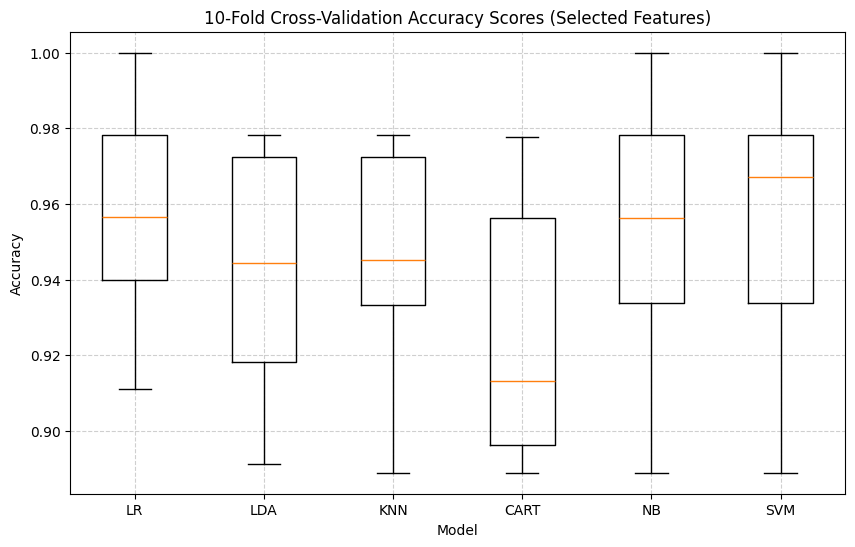

In [77]:
# TODO: box plot of the 10 fold scores per model
...

import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))
plt.boxplot(selected_scaled_results.values(), labels=selected_scaled_results.keys())
plt.title("10-Fold Cross-Validation Accuracy Scores (Selected Features)")
plt.ylabel("Accuracy")
plt.xlabel("Model")
plt.grid(True, linestyle="--", alpha=0.6)
plt.show()

**Exercise D.6.** In a medical setting accuracy is not enough. For the best scaled model, cross-validate **accuracy, ROC-AUC and recall for the malignant class** (`pos_label=0`).

In [76]:
# TODO: cross_validate with a scoring dict including make_scorer(recall_score, pos_label=0)
...
from sklearn.model_selection import GridSearchCV

param_grid = {
    "model__C": [0.1, 1, 10, 100],
    "model__gamma": ["scale", "auto", 0.01, 0.1]
}

grid = GridSearchCV(
    Pipeline([("scale", StandardScaler()), ("model", SVC(random_state=seed))]),
    param_grid,
    cv=kfold,
    scoring="accuracy"
)
grid.fit(X_train[consensus_features], y_train)

print("Best parameters:", grid.best_params_)
print("Best cross-validation score:", grid.best_score_)

Best parameters: {'model__C': 100, 'model__gamma': 'scale'}
Best cross-validation score: 0.9692270531400966


---
## E. Improve Accuracy

### E.1 Algorithm Tuning
**Exercise E.1.** Tune the SVM (`C`, `gamma`, `kernel`) with `GridSearchCV` inside a scaling pipeline.

In [78]:
# TODO: grid search over C=[0.1,1,10,100], gamma=["scale",0.001,0.01,0.1], kernel=["rbf","linear"]
...

svm_pipe = Pipeline([
    ("scale", StandardScaler()),
    ("model", SVC(random_state=seed))
])

svm_param_grid = {
    "model__C": [0.1, 1, 10, 100],
    "model__gamma": ["scale", 0.001, 0.01, 0.1],
    "model__kernel": ["rbf", "linear"]
}

svm_grid = GridSearchCV(svm_pipe, svm_param_grid, cv=kfold, scoring="accuracy")
svm_grid.fit(X_train[consensus_features], y_train)

print("SVM Best Parameters:", svm_grid.best_params_)
print("SVM Best Cross-Validation Score:", svm_grid.best_score_)

SVM Best Parameters: {'model__C': 100, 'model__gamma': 'scale', 'model__kernel': 'rbf'}
SVM Best Cross-Validation Score: 0.9692270531400966


**Exercise E.2.** Tune KNN (`n_neighbors`, `weights`) the same way.

In [79]:
# TODO: grid over n_neighbors=[3,5,7,9,11,15,21] and weights=["uniform","distance"]
...

knn_pipe = Pipeline([
    ("scale", StandardScaler()),
    ("model", KNeighborsClassifier())
])

knn_param_grid = {
    "model__n_neighbors": [3, 5, 7, 9, 11, 15, 21],
    "model__weights": ["uniform", "distance"]
}

knn_grid = GridSearchCV(knn_pipe, knn_param_grid, cv=kfold, scoring="accuracy")
knn_grid.fit(X_train[consensus_features], y_train)

print("KNN Best Parameters:", knn_grid.best_params_)
print("KNN Best Cross-Validation Score:", knn_grid.best_score_)

KNN Best Parameters: {'model__n_neighbors': 21, 'model__weights': 'uniform'}
KNN Best Cross-Validation Score: 0.9537681159420291


### E.2 Ensembles
**Exercise E.3.** Spot-check four ensemble methods (Random Forest, Extra Trees, Gradient Boosting, AdaBoost) and one voting ensemble of the tuned SVM, tuned KNN and Random Forest.

In [80]:
# TODO: dictionary ensembles, score with spot_check(scale=False), then a hard VotingClassifier
...

from sklearn.ensemble import RandomForestClassifier, ExtraTreesClassifier, AdaBoostClassifier, GradientBoostingClassifier, VotingClassifier

ensembles = {
    "RF": RandomForestClassifier(random_state=seed),
    "ET": ExtraTreesClassifier(random_state=seed),
    "AB": AdaBoostClassifier(random_state=seed),
    "GB": GradientBoostingClassifier(random_state=seed),
    "Voting": VotingClassifier(estimators=[
        ("lr", LogisticRegression(random_state=seed)),
        ("svm", SVC(random_state=seed)),
        ("knn", KNeighborsClassifier())
    ], voting="hard")
}

ensemble_results = spot_check(ensembles, X_train[consensus_features], scale=False)
for name, scores in ensemble_results.items():
    print(f"{name}: {scores.mean():.4f} (+/- {scores.std():.4f})")

RF: 0.9538 (+/- 0.0305)
ET: 0.9583 (+/- 0.0287)
AB: 0.9451 (+/- 0.0330)
GB: 0.9472 (+/- 0.0328)
Voting: 0.9295 (+/- 0.0280)


**Exercise E.4.** Build a leaderboard (Series sorted by mean CV accuracy) containing both tuned models, the four ensembles and the voting ensemble.

In [81]:
# TODO: leaderboard Series
...

all_results = {
    **{k: v.mean() for k, v in selected_scaled_results.items()},
    **{k: v.mean() for k, v in ensemble_results.items()}
}
leaderboard = pd.Series(all_results).sort_values(ascending=False)
print(leaderboard)

LR        0.960435
ET        0.958261
SVM       0.953865
RF        0.953816
NB        0.951691
GB        0.947246
AB        0.945072
LDA       0.942995
KNN       0.942802
Voting    0.929517
CART      0.925266
dtype: float64


### E.3 Finalize the Model
**Exercise E.5.** Fit the winner on the full training set and, for the first and only time, evaluate it on the held-out **test set**. Report accuracy, the classification report and a confusion matrix.

              precision    recall  f1-score   support

           0       0.91      0.93      0.92        42
           1       0.96      0.94      0.95        72

    accuracy                           0.94       114
   macro avg       0.93      0.94      0.93       114
weighted avg       0.94      0.94      0.94       114



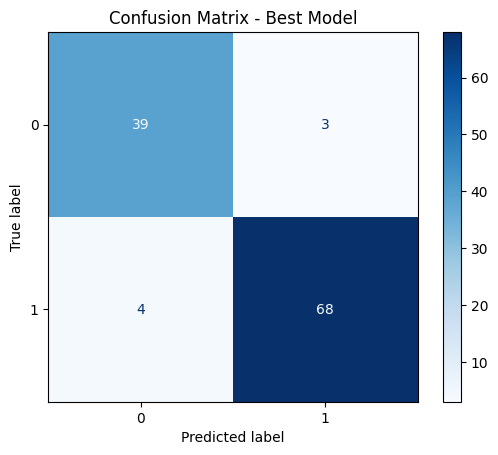

In [83]:
# TODO: pick the leaderboard winner, fit on train, predict test, print metrics, plot confusion matrix
...
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

best_model = svm_grid.best_estimator_
best_model.fit(X_train[consensus_features], y_train)
y_pred = best_model.predict(X_test[consensus_features])

print(classification_report(y_test, y_pred))

cm = confusion_matrix(y_test, y_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm)
disp.plot(cmap=plt.cm.Blues)
plt.title("Confusion Matrix - Best Model")
plt.show()

**Exercise E.6.** Save the model with `joblib`, reload it and confirm it reproduces predictions.

In [84]:
# TODO: joblib.dump, joblib.load, compare first 5 predictions with y_test
...

import joblib

joblib.dump(best_model, "best_model.pkl")
loaded_model = joblib.load("best_model.pkl")

loaded_preds = loaded_model.predict(X_test[consensus_features])
print("First 5 predictions:", loaded_preds[:5])
print("First 5 actual:", y_test.iloc[:5].values if hasattr(y_test, 'iloc') else y_test[:5])

First 5 predictions: [0 0 1 0 1]
First 5 actual: [0 0 1 0 1]


---
## Reflection Questions
✏️ Answer in a short paragraph each.

1. **Leakage.** Feature selection in Part C used the whole dataset. Explain why this can inflate CV scores and how you would fix it using a `Pipeline`.

>*Leakage. Performing feature selection on the entire dataset leaks target information into validation folds, causing artificially inflated CV scores. To fix this, feature selection and scaling must be encapsulated entirely within a scikit-learn Pipeline so they are re-fitted strictly within each training fold.*


2. **Metric choice.** Which metric would you report to a clinician, and why is accuracy alone insufficient?

>*Metric choice. For medical diagnosis, accuracy alone is misleading because it ignores the severe cost of false negatives. We must report recall for the malignant class and precision to ensure we catch actual cancer cases while minimizing false alarms.*

3. **Model choice.** If two models differ by 0.3% in CV accuracy, how would you decide between them? (Think variance across folds, interpretability, training cost.)

>*Model choice. A 0.3% difference in accuracy is statistically negligible and falls within fold variation. Tie-breaking should rely on score stability (low variance across folds), model interpretability for clinicians, and deployment latency.*

4. **Generalization.** How would your conclusions change with a much smaller or much more imbalanced dataset?

>*Generalization. A much smaller dataset increases the risk of overfitting, requiring simpler models and stronger regularization. A heavily imbalanced dataset renders standard accuracy misleading, requiring metrics like PR-AUC and F1-score.*

5. **Extension.** Repeat the workbook with a dataset of your choice (e.g., loaded from an ARFF file) and note which steps change.

>*Extension. Adapting to a new dataset (like an ARFF file) changes initial data loading, requires adding categorical encoding steps for non-numerical features, and calls for domain-specific preprocessing and evaluation metrics.*

**Submission checklist:** all `TODO`s completed · all cells run top to bottom · written answers filled in · final test accuracy reported once.